# Predicting Default on SBA-Guaranteed Small-Business Loans: A Job-Creation Lens

**Task:** binary classification. For each SBA-guaranteed loan, predict whether it will be **charged off (default = 1)** or **paid in full (default = 0)**.

**Why this matters :** small businesses are a major source of new jobs. The SBA guarantees part of a bank loan so that lenders will finance firms they would otherwise refuse. A model that is too cautious rejects repayable loans, and every wrongly rejected loan is a lost chance to create jobs. A model that is too lenient costs lenders and taxpayers. The experiments therefore look not only at overall accuracy but at *who* the model wrongly flags, in particular loans that plan to create jobs and new businesses.

**Dataset:** U.S. SBA loan records, 1987 to 2014 (about 899k rows, 27 columns; the notebook warns if a partial file is loaded), published with Li, Mickel and Taylor (2018), *Journal of Statistics Education* 26(1), 55-66, doi:10.1080/10691898.2018.1434342. Download it from Kaggle (see Section 1).

**Notebook map**

| Section | Content |
|---|---|
| 0 | Setup, configuration, seeds |
| 1 | Load the raw data and check the 20,000-row requirement |
| 2 | Cleaning and **leakage removal** |
| 3 | Exploratory analysis |
| 4 | Feature engineering, splits, preprocessing pipeline |
| 5 | Experiment infrastructure (metrics, logging to W&B offline and TensorBoard) |
| 6 | Experiments E1 to E6, traditional ML (scikit-learn) |
| 7 | Experiments E7 to E9, deep learning (Keras, `tf.data`) |
| 8 | E10 threshold tuning and E11 time-based split |
| 9 | Final evaluation on the held-out test set, learning curves, error analysis |
| 10 | Experiment table, saving models, Drive export |



## 0. Setup and reproducibility

Colab already ships with TensorFlow, scikit-learn, pandas and matplotlib. Only two extra packages are needed. Locally, use `pip install -r requirements.txt` instead.

In [1]:
%pip install -q kagglehub wandb tabulate

In [2]:
import os, random, time, json, shutil, warnings, importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score, matthews_corrcoef,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

import tensorflow as tf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50, "display.width", 160)
print("TensorFlow", tf.__version__, "| pandas", pd.__version__)

TensorFlow 2.21.0 | pandas 2.2.3


In [3]:
# ------------------------------- CONFIGURATION -------------------------------
SEED = 42
FAST_DEBUG = False          # True = tiny run (seconds) just to check the notebook works end to end

DATA_PATH = None            # e.g. "/content/SBAnational.csv"; None = search common places, then try kagglehub
MAX_APPROVAL_FY = 2010      # design choice, see Section 2 (reduces right-censored outcomes)

VAL_FRAC, TEST_FRAC = 0.15, 0.15          # random stratified split: 70 / 15 / 15
TIME_TRAIN_END, TIME_VAL_END = 2005, 2006   # time split: train FY<=2005, validate FY 2006, test FY>2006 (auto-adjusted if the data lack these years)

TUNE_ROWS         = 5_000 if FAST_DEBUG else 100_000   # rows used inside hyper-parameter searches
RF_MAX_TRAIN_ROWS = 5_000 if FAST_DEBUG else 250_000   # cap for random-forest fits (time/memory trade-off)
SEARCH_ITER       = 2 if FAST_DEBUG else 10
CV_FOLDS          = 2 if FAST_DEBUG else 3
NN_EPOCHS         = 2 if FAST_DEBUG else 30
NN_BATCH          = 2048
NN_TRIALS         = 2 if FAST_DEBUG else 6
NN_CLASS_WEIGHT   = True    # weight the minority (default) class in the Keras loss

WANDB_PROJECT = "sba-job-creation-default"
OUT        = Path("outputs")
MODELS_DIR = OUT / "models"
RESULTS_DIR = OUT / "results"
FIGS_DIR   = OUT / "figures"
TB_DIR     = OUT / "tensorboard"
WANDB_DIR  = OUT / "wandb"
for d in (MODELS_DIR, RESULTS_DIR, FIGS_DIR, TB_DIR, WANDB_DIR):
    d.mkdir(parents=True, exist_ok=True)

os.environ["WANDB_MODE"] = "offline"   # required by the brief: W&B offline mode
os.environ["WANDB_SILENT"] = "true"

def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_seeds()

## 1. Load the raw data

**Where to get it**

1. Kaggle: <https://www.kaggle.com/datasets/mirbektoktogaraev/should-this-loan-be-approved-or-denied> (free account; the file you need is `SBAnational.csv`). Check the licence shown on that page before you redistribute the file.
2. Original publication (cite this in your report): Li, M., Mickel, A., and Taylor, S. (2018). "Should This Loan be Approved or Denied?": A Large Dataset with Class Assignment Guidelines. *Journal of Statistics Education*, 26(1), 55-66. <https://doi.org/10.1080/10691898.2018.1434342>
3. Underlying source: U.S. Small Business Administration loan data.

**How to load it in Colab (pick one)**

* Upload `SBAnational.csv` with the Files panel on the left, then leave `DATA_PATH = None`; the loader looks in `/content/`.
* Or put it in Google Drive and set `DATA_PATH = "/content/drive/MyDrive/.../SBAnational.csv"` after mounting Drive.
* Or let the cell try `kagglehub` (works for public datasets; if it fails, use one of the two options above).



In [4]:
def locate_dataset(explicit=DATA_PATH):
    # Return the path to SBAnational.csv.
    if explicit and Path(explicit).exists():
        return Path(explicit)
    for p in ["SBAnational.csv", "data/SBAnational.csv", "/content/SBAnational.csv",
              "/content/drive/MyDrive/SBAnational.csv", "/kaggle/input/should-this-loan-be-approved-or-denied/SBAnational.csv"]:
        if Path(p).exists():
            return Path(p)
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download("mirbektoktogaraev/should-this-loan-be-approved-or-denied"))
        csvs = list(folder.rglob("*.csv"))
        national = [f for f in csvs if "national" in f.name.lower()]
        return (national or sorted(csvs, key=lambda f: f.stat().st_size))[-1]
    except Exception as e:
        raise FileNotFoundError(
            "Could not find SBAnational.csv. Download it from Kaggle (link above), upload it to Colab, "
            f"and set DATA_PATH. Original error: {e}")

data_path = locate_dataset()
raw = pd.read_csv(data_path, dtype={"NAICS": str, "Zip": str, "ApprovalFY": str}, low_memory=False)
print("Loaded:", data_path)
print("Raw shape:", raw.shape)
assert len(raw) >= 20_000, "Brief requires >= 20,000 raw rows"
if len(raw) < 800_000:
    print(f"WARNING: the Kaggle SBAnational.csv has ~899k rows but only {len(raw):,} were loaded. "
          "The file is probably a partial upload: delete it and set DATA_PATH = None so kagglehub downloads the full file.")
raw.head(3)

100%|██████████| 46.4M/46.4M [00:00<00:00, 143MB/s]

Extracting files...


Loaded: /root/.cache/kagglehub/datasets/mirbektoktogaraev/should-this-loan-be-approved-or-denied/versions/2/SBAnational.csv
Raw shape: (899164, 27)


,LoanNr_ChkDgt,Name,City,State,Zip,Bank,BankState,NAICS,ApprovalDate,ApprovalFY,Term,NoEmp,NewExist,CreateJob,RetainedJob,FranchiseCode,UrbanRural,RevLineCr,LowDoc,ChgOffDate,DisbursementDate,DisbursementGross,BalanceGross,MIS_Status,ChgOffPrinGr,GrAppv,SBA_Appv
0,1000014003,ABC HOBBYCRAFT,EVANSVILLE,IN,47711,FIFTH THIRD BANK,OH,451120,28-Feb-97,1997,84,4,2.0,0,0,1,0,N,Y,NaN,28-Feb-99,"$60,000.00",$0.00,P I F,$0.00,"$60,000.00","$48,000.00"
1,1000024006,LANDMARK BAR & GRILLE (THE),NEW PARIS,IN,46526,1ST SOURCE BANK,IN,722410,28-Feb-97,1997,60,2,2.0,0,0,1,0,N,Y,NaN,31-May-97,"$40,000.00",$0.00,P I F,$0.00,"$40,000.00","$32,000.00"
2,1000034009,"WHITLOCK DDS, TODD M.",BLOOMINGTON,IN,47401,GRANT COUNTY STATE BANK,IN,621210,28-Feb-97,1997,180,7,1.0,0,0,1,0,N,N,NaN,31-Dec-97,"$287,000.00",$0.00,P I F,$0.00,"$287,000.00","$215,250.00"


## 2. Cleaning and leakage removal

Decisions made here

| Decision | Reason |
|---|---|
| Keep only rows whose `MIS_Status` is `CHGOFF` or `P I F`; target `Default = 1` for `CHGOFF` | Rows with a missing label cannot be used for supervised learning |
| **Drop `ChgOffDate`, `ChgOffPrinGr`, `BalanceGross`** | They only exist or are non-zero *after* a default happens, so using them would leak the answer |
| Drop identifiers and free text (`LoanNr_ChkDgt`, `Name`, `City`, `Zip`, `Bank`) | No generalisable signal, very high cardinality, and `Name` identifies businesses |
| Parse dollar strings such as `"$60,000.00 "` into numbers | They are stored as text |
| Keep `NewExist` in {1, 2}; map `RevLineCr`, `LowDoc` to Y / N / UNK | Other codes are undocumented noise |
| Keep loans with `ApprovalFY <= MAX_APPROVAL_FY` (2010) | Loans approved late in the window have not had time to mature or default before the data ends in 2014, so a "paid in full" label is partly an artefact of censoring. **Verify this choice against the paper's discussion of the data and justify it in your report.** |
| Two-digit NAICS sector instead of the 6-digit code | The full code is too sparse |

In [5]:
LEAKAGE_COLS = ["ChgOffDate", "ChgOffPrinGr", "BalanceGross"]
DROP_ID_COLS = ["LoanNr_ChkDgt", "Name", "City", "Zip", "Bank"]
MONEY_COLS   = ["DisbursementGross", "GrAppv", "SBA_Appv"]
REQUIRED = ["MIS_Status", "State", "BankState", "NAICS", "ApprovalDate", "ApprovalFY", "DisbursementDate",
            "Term", "NoEmp", "NewExist", "CreateJob", "RetainedJob", "FranchiseCode", "UrbanRural",
            "RevLineCr", "LowDoc", "DisbursementGross", "GrAppv", "SBA_Appv"]

def money_to_float(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[$,\s]", "", regex=True), errors="coerce")

def clean_raw(raw_df, max_fy=MAX_APPROVAL_FY):
    # Return (clean_df, row-count log). Every step is deterministic.
    missing = [c for c in REQUIRED if c not in raw_df.columns]
    assert not missing, f"Columns not found: {missing}. Are you loading SBAnational.csv?"
    log = {"raw rows": len(raw_df)}
    df = raw_df.copy()

    status = df["MIS_Status"].astype(str).str.replace(" ", "", regex=False).str.upper()
    df = df.loc[status.isin(["CHGOFF", "PIF"])].copy()
    df["Default"] = (status.loc[df.index] == "CHGOFF").astype(int)
    log["with valid label"] = len(df)

    for c in MONEY_COLS:
        df[c] = money_to_float(df[c])
    df["ApprovalDate"] = pd.to_datetime(df["ApprovalDate"], format="%d-%b-%y", errors="coerce")
    df["DisbursementDate"] = pd.to_datetime(df["DisbursementDate"], format="%d-%b-%y", errors="coerce")
    df["ApprovalFY"] = pd.to_numeric(df["ApprovalFY"].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")
    for c in ["Term", "NoEmp", "CreateJob", "RetainedJob", "FranchiseCode", "NewExist", "UrbanRural"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df[df["ApprovalFY"].le(max_fy)]
    log[f"approved FY <= {max_fy}"] = len(df)
    df = df[df["NewExist"].isin([1, 2]) & df["Term"].gt(0) & df["GrAppv"].gt(0)]
    log["valid NewExist / Term / GrAppv"] = len(df)

    naics2 = df["NAICS"].astype(str).str.extract(r"^(\d{2})")[0]
    df["NAICS2"] = naics2.where(naics2 != "00").fillna("UNK")
    for c in ["RevLineCr", "LowDoc"]:
        v = df[c].astype(str).str.upper().str.strip()
        df[c] = v.where(v.isin(["Y", "N"]), "UNK")
    for c in ["State", "BankState"]:
        df[c] = df[c].astype("object").where(df[c].notna(), "UNK").astype(str).str.upper().str.strip()
    df["UrbanRural"] = df["UrbanRural"].fillna(0).astype(int).astype(str)
    df["NewExist"] = df["NewExist"].astype(int).astype(str)

    df = df.drop(columns=[c for c in LEAKAGE_COLS + DROP_ID_COLS if c in df.columns])
    return df.reset_index(drop=True), log

df_clean, clean_log = clean_raw(raw)
print(pd.Series(clean_log, name="rows").to_frame())
print("\nLeakage columns removed:", LEAKAGE_COLS)
assert not set(LEAKAGE_COLS) & set(df_clean.columns)
print(f"\nApproval years kept: {int(df_clean['ApprovalFY'].min())} to {int(df_clean['ApprovalFY'].max())}")
print("Loans per approval year (last 8 years):"); print(df_clean["ApprovalFY"].value_counts().sort_index().tail(8).to_string())
if len(df_clean) < 0.5 * len(raw):
    print("\nWARNING: more than half of the raw rows were removed. Check the row counts above to see which step dropped them, "
          "and make sure you loaded the complete SBAnational.csv.")
df_clean.head(3)

                                  rows
raw rows                        899164
with valid label                897167
approved FY <= 2010             875859
valid NewExist / Term / GrAppv  873937

Leakage columns removed: ['ChgOffDate', 'ChgOffPrinGr', 'BalanceGross']

Approval years kept: 1969 to 2010
Loans per approval year (last 8 years):
ApprovalFY
2003    57751
2004    67993
2005    76847
2006    75598
2007    71553
2008    39421
2009    19092
2010    16734


,State,BankState,NAICS,ApprovalDate,ApprovalFY,Term,NoEmp,NewExist,CreateJob,RetainedJob,FranchiseCode,UrbanRural,RevLineCr,LowDoc,DisbursementDate,DisbursementGross,MIS_Status,GrAppv,SBA_Appv,Default,NAICS2
0,IN,OH,451120,1997-02-28,1997,84,4,2,0,0,1,0,N,Y,1999-02-28,60000.0,P I F,60000.0,48000.0,0,45
1,IN,IN,722410,1997-02-28,1997,60,2,2,0,0,1,0,N,Y,1997-05-31,40000.0,P I F,40000.0,32000.0,0,72
2,IN,IN,621210,1997-02-28,1997,180,7,1,0,0,1,0,N,N,1997-12-31,287000.0,P I F,287000.0,215250.0,0,62


## 3. Exploratory analysis

The goals are to understand class balance, missingness, outliers and how the job-creation columns relate to default.

               loans  share
Default                    
Paid in full  718589  0.822
Charged off   155348  0.178

Missing values in raw file (top 8, share of rows):
ChgOffDate          0.819
RevLineCr           0.005
LowDoc              0.003
DisbursementDate    0.003
MIS_Status          0.002
BankState           0.002
Bank                0.002
NewExist            0.000
dtype: float64

Numeric summary (note the extreme maxima, which motivate winsorising):
                      count      mean       std     min       50%        99%      99.9%         max
Term               873937.0     111.5      79.1     1.0      84.0      300.0      309.0       569.0
NoEmp              873937.0      11.4      74.4     0.0       4.0       95.0      300.0      9999.0
CreateJob          873937.0       8.5     239.3     0.0       0.0       30.0      200.0      8800.0
RetainedJob        873937.0      10.8     239.8     0.0       1.0       53.0      286.1      9500.0
GrAppv             873937.0  190801.2  27

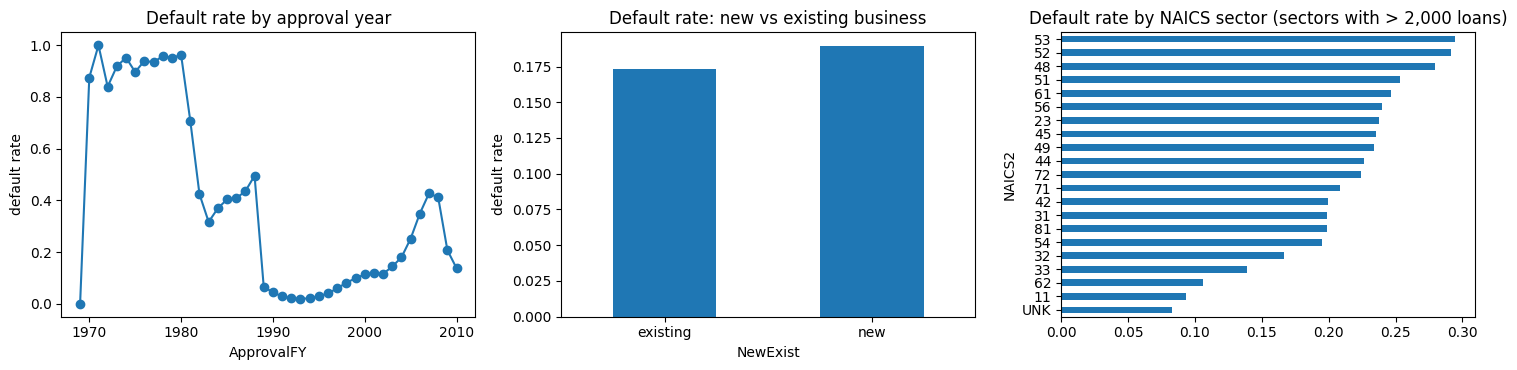

In [6]:
target_counts = df_clean["Default"].value_counts().rename({0: "Paid in full", 1: "Charged off"})
print(target_counts.to_frame("loans").assign(share=lambda t: (t.loans / t.loans.sum()).round(3)))

print("\nMissing values in raw file (top 8, share of rows):")
print(raw.isna().mean().sort_values(ascending=False).head(8).round(3))

num_summary = df_clean[["Term", "NoEmp", "CreateJob", "RetainedJob", "GrAppv", "SBA_Appv", "DisbursementGross"]].describe(
    percentiles=[.5, .99, .999]).T
print("\nNumeric summary (note the extreme maxima, which motivate winsorising):")
print(num_summary.round(1))

df_clean["_CreatesJobs"] = (df_clean["CreateJob"] > 0).astype(int)
tab = (df_clean.groupby("_CreatesJobs")["Default"].agg(loans="size", default_rate="mean").rename(
    index={0: "plans no new jobs", 1: "plans to create jobs"}).round(3))
print("\nDefault rate by whether the loan plans to create jobs:")
print(tab)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
df_clean.groupby("ApprovalFY")["Default"].mean().plot(ax=ax[0], marker="o")
ax[0].set(title="Default rate by approval year", ylabel="default rate")
df_clean.groupby("NewExist")["Default"].mean().rename(index={"1": "existing", "2": "new"}).plot.bar(ax=ax[1], rot=0)
ax[1].set(title="Default rate: new vs existing business", ylabel="default rate")
df_clean.groupby("NAICS2")["Default"].agg(["mean", "size"]).query("size > 2000")["mean"].sort_values().plot.barh(ax=ax[2])
ax[2].set(title="Default rate by NAICS sector (sectors with > 2,000 loans)")
plt.tight_layout(); plt.savefig(FIGS_DIR / "eda_default_rates.png", dpi=150); plt.show()
df_clean = df_clean.drop(columns="_CreatesJobs")

** interpretation (EDA).** Write 4 to 6 sentences in your own words: How imbalanced is the target and what does that imply for accuracy as a metric? What does the default-rate-by-year plot suggest about the 2007 to 2009 recession and about a random versus a time-based split? Do loans that plan to create jobs default more or less often, and what might explain it?

## 4. Feature engineering, splitting and preprocessing

**Two feature sets** let us measure the effect of feature engineering directly (E1 vs E2):

* `base`: the cleaned original columns.
* `engineered`: adds guarantee ratio, disbursed-to-approved ratio, log loan size, total and per-employee jobs, approval-to-disbursement lag, and flags for job creation, same-state bank, franchise, and a loan being active during the Dec 2007 to Jun 2009 recession (NBER dates).

All engineered features are computed row by row from information known at approval or disbursement, so they cannot leak the outcome.

**Preprocessing (fitted on the training split only, inside a scikit-learn pipeline):** winsorise numerics at the 0.5th and 99.5th percentiles, median-impute, standardise; impute and one-hot encode categoricals (rare levels pooled).

**Splits:** the main experiments use a stratified random 70/15/15 split with a fixed seed. Experiment E11 repeats the best models on a **time-based split** to test robustness to the recession.

In [7]:
RECESSION_START, RECESSION_END = pd.Timestamp("2007-12-01"), pd.Timestamp("2009-06-30")

def add_engineered_features(d):
    out = d.copy()
    out["Guarantee_ratio"] = out["SBA_Appv"] / out["GrAppv"]
    out["Disb_ratio"] = out["DisbursementGross"] / out["GrAppv"]
    out["log_GrAppv"] = np.log1p(out["GrAppv"])
    out["Jobs_total"] = out["CreateJob"] + out["RetainedJob"]
    out["Jobs_per_emp"] = out["Jobs_total"] / out["NoEmp"].clip(lower=1)
    out["Disb_lag_days"] = (out["DisbursementDate"] - out["ApprovalDate"]).dt.days
    out["CreatesJobs"] = (out["CreateJob"] > 0).astype(int)
    out["SameState"] = (out["State"] == out["BankState"]).astype(int)
    out["IsFranchise"] = (out["FranchiseCode"] > 1).astype(int)   # codes 0 and 1 mean "no franchise"
    loan_end = out["DisbursementDate"] + pd.to_timedelta(out["Term"] * 30.44, unit="D")
    out["ActiveDuringRecession"] = ((out["DisbursementDate"] <= RECESSION_END) & (loan_end >= RECESSION_START)).astype(int)
    return out

df = add_engineered_features(df_clean)

BASE_NUM = ["Term", "NoEmp", "CreateJob", "RetainedJob", "GrAppv", "SBA_Appv", "DisbursementGross", "FranchiseCode"]
BASE_CAT = ["State", "BankState", "NAICS2", "NewExist", "UrbanRural", "RevLineCr", "LowDoc"]
ENG_NUM  = ["Guarantee_ratio", "Disb_ratio", "log_GrAppv", "Jobs_total", "Jobs_per_emp", "Disb_lag_days"]
ENG_BIN  = ["CreatesJobs", "SameState", "IsFranchise", "ActiveDuringRecession"]

FEATURE_SETS = {                       # name: (numeric, binary, categorical)
    "base":       (BASE_NUM,            [],      BASE_CAT),
    "engineered": (BASE_NUM + ENG_NUM,  ENG_BIN, BASE_CAT),
}
y_all = df["Default"].to_numpy()

def get_X(d, feature_set):
    num, binary, cat = FEATURE_SETS[feature_set]
    X = d[num + binary + cat].copy()
    X[cat] = X[cat].astype(str)
    return X

TIME_CUTOFFS = {}

def resolve_time_cutoffs(d):
    # Use the configured years if every split would be non-empty; otherwise pick 70/15/15 cut-offs by loan count.
    fy = d["ApprovalFY"].to_numpy()
    if (fy <= TIME_TRAIN_END).any() and ((fy > TIME_TRAIN_END) & (fy <= TIME_VAL_END)).any() and (fy > TIME_VAL_END).any():
        return TIME_TRAIN_END, TIME_VAL_END
    counts = d["ApprovalFY"].value_counts().sort_index()
    years = [int(y) for y in counts.index]
    if len(years) < 3:
        raise ValueError(f"Time split needs at least 3 approval years, found {years}. Check the cleaning log in Section 2.")
    cum = (counts.cumsum() / counts.sum()).to_numpy()
    i_tr = min(int(np.searchsorted(cum, 0.70)), len(years) - 3)
    i_va = min(max(int(np.searchsorted(cum, 0.85)), i_tr + 1), len(years) - 2)
    print(f"[time split] configured years do not fit the data (years present: {years[0]}-{years[-1]}); "
          f"using train FY<={years[i_tr]}, validate FY<={years[i_va]}, test FY>{years[i_va]}")
    return years[i_tr], years[i_va]

def make_split_indices(d, mode="random"):
    idx, y = np.arange(len(d)), d["Default"].to_numpy()
    if mode == "random":
        tr_val, te = train_test_split(idx, test_size=TEST_FRAC, stratify=y, random_state=SEED)
        tr, va = train_test_split(tr_val, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=y[tr_val], random_state=SEED)
    elif mode == "time":
        fy = d["ApprovalFY"].to_numpy()
        a, b = resolve_time_cutoffs(d)
        TIME_CUTOFFS.update(train_end=a, val_end=b)
        tr, va, te = idx[fy <= a], idx[(fy > a) & (fy <= b)], idx[fy > b]
    else:
        raise ValueError(mode)
    assert min(len(tr), len(va), len(te)) > 0, f"Empty split in mode '{mode}': {len(tr)}/{len(va)}/{len(te)}"
    return {"train": tr, "val": va, "test": te}

def describe_splits(splits, d):
    rows = {k: {"rows": len(v), "default_rate": d["Default"].to_numpy()[v].mean()} for k, v in splits.items()}
    return pd.DataFrame(rows).T.round(3)

SPLITS = make_split_indices(df, "random")
print("Random stratified split"); print(describe_splits(SPLITS, df))
print("\nTime-based split (used in E11)"); print(describe_splits(make_split_indices(df, "time"), df))

Random stratified split
           rows  default_rate
train  611755.0         0.178
val    131091.0         0.178
test   131091.0         0.178

Time-based split (used in E11)
           rows  default_rate
train  651539.0         0.117
val     75598.0         0.349
test   146800.0         0.361


In [8]:
class Winsorizer(TransformerMixin, BaseEstimator):
    # Clip each column to quantiles learned on the training data only.
    def __init__(self, lower=0.005, upper=0.995):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

def make_preprocessor(num_cols, bin_cols, cat_cols):
    numeric = Pipeline([("win", Winsorizer()), ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    binary = SimpleImputer(strategy="constant", fill_value=0)
    categorical = Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="UNK")),
        ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.001,
                             sparse_output=False, dtype=np.float32))])
    return ColumnTransformer([("num", numeric, num_cols), ("bin", binary, bin_cols), ("cat", categorical, cat_cols)],
                             remainder="drop")

Xb = make_preprocessor(*FEATURE_SETS["engineered"]).fit(get_X(df.iloc[SPLITS["train"]], "engineered"))
print("Engineered feature matrix width after encoding:", Xb.transform(get_X(df.iloc[SPLITS["train"][:5]], "engineered")).shape[1])

Engineered feature matrix width after encoding: 157


## 5. Experiment infrastructure

* **Positive class = default (1).** Metrics reported: accuracy, balanced accuracy, precision, recall, F1, Matthews correlation, ROC-AUC and PR-AUC. On an imbalanced target, PR-AUC and recall on the default class are more informative than accuracy.
* **Model selection uses the validation split only.** The test split is touched once, in Section 9.
* Every run is written to the results table, to a **Weights and Biases offline** run (`outputs/wandb`) and, for Keras, to **TensorBoard** (`outputs/tensorboard`). That makes each number in the table traceable to a logged run.
* Training AUC is recorded next to validation AUC so the gap (a variance indicator) can be discussed.

In [9]:
def evaluate(y_true, proba, threshold=0.5):
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "balanced_acc": balanced_accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "mcc": matthews_corrcoef(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}

RESULTS = []          # rows of the experiment table
STORE = {}            # exp_id -> fitted objects and validation probabilities
HISTORIES = {}        # exp_id -> Keras training history

def _jsonable(d):
    return {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in d.items()}

def log_run(exp_id, name, paradigm, feature_set, split_name, params, metrics, train_auc=None,
            fit_seconds=None, eval_set="val", in_table=True):
    row = {"exp": exp_id, "model": name, "paradigm": paradigm, "features": feature_set, "split": split_name,
           "eval_on": eval_set, "params": json.dumps(_jsonable(params), default=str),
           **{k: round(float(v), 4) for k, v in metrics.items()},
           "train_roc_auc": None if train_auc is None else round(float(train_auc), 4),
           "auc_gap": None if train_auc is None else round(float(train_auc - metrics["roc_auc"]), 4),
           "fit_seconds": None if fit_seconds is None else round(float(fit_seconds), 1)}
    if in_table:
        RESULTS.append(row)
    try:
        import wandb
        run = wandb.init(project=WANDB_PROJECT, name=f"{exp_id}-{name}", dir=str(WANDB_DIR), mode="offline",
                         config=_jsonable({"paradigm": paradigm, "features": feature_set, "split": split_name,
                                           "eval_on": eval_set, **params}))
        run.log({f"{eval_set}_{k}": float(v) for k, v in metrics.items()})
        if train_auc is not None:
            run.log({"train_roc_auc": float(train_auc)})
        run.finish()
    except Exception as e:        # logging must never break the experiment
        print(f"[wandb offline logging skipped: {e}]")
    return row

def show(row):
    keys = ["exp", "model", "features", "eval_on", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_roc_auc", "auc_gap", "fit_seconds"]
    print(pd.Series({k: row[k] for k in keys}).to_string())

## 6. Traditional machine learning (scikit-learn)

The first six experiments each change **one main thing** relative to an earlier run so the table shows progression:

| Exp | Model | What changes |
|---|---|---|
| E1 | Logistic regression | Baseline, `base` features |
| E2 | Logistic regression | + engineered features |
| E3 | Logistic regression | + class weighting (`balanced`) |
| E4 | Random forest | Non-linear model, default-style settings |
| E5 | Random forest | Randomised hyper-parameter search |
| E6 | Histogram gradient boosting | Randomised search, including class weighting |

In [10]:
def sample_rows(idx, n, seed=SEED):
    if n is None or len(idx) <= n:
        return idx
    return np.random.RandomState(seed).choice(idx, n, replace=False)

def make_pipeline(feature_set, estimator):
    return Pipeline([("prep", make_preprocessor(*FEATURE_SETS[feature_set])), ("clf", estimator)])

def tune(feature_set, estimator, param_dist, scoring="average_precision"):
    # Randomised search on a subsample of the TRAIN split (3-fold, stratified). Returns the best params.
    pipe = make_pipeline(feature_set, estimator)
    idx = sample_rows(SPLITS["train"], TUNE_ROWS)
    search = RandomizedSearchCV(pipe, param_dist, n_iter=SEARCH_ITER, scoring=scoring,
                                cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED),
                                random_state=SEED, refit=False, n_jobs=1, verbose=0)
    search.fit(get_X(df.iloc[idx], feature_set), y_all[idx])
    res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    best = res.iloc[0]["params"]
    return best, res[["params", "mean_test_score", "std_test_score", "rank_test_score"]]

def run_classical(exp_id, name, estimator, feature_set="engineered", fit_rows=None, tune_space=None, split_name="random"):
    set_seeds()
    tuning_table = None
    if tune_space is not None:
        best, tuning_table = tune(feature_set, estimator, tune_space)
        pipe = make_pipeline(feature_set, estimator).set_params(**best)
        print(f"[{exp_id}] best params from search:", {k.replace('clf__', ''): v for k, v in best.items()})
    else:
        pipe = make_pipeline(feature_set, estimator)
    tr = sample_rows(SPLITS["train"], fit_rows)
    t0 = time.time()
    pipe.fit(get_X(df.iloc[tr], feature_set), y_all[tr])
    secs = time.time() - t0
    va = SPLITS["val"]
    p_val = pipe.predict_proba(get_X(df.iloc[va], feature_set))[:, 1]
    tr_eval = sample_rows(SPLITS["train"], 100_000)
    auc_tr = roc_auc_score(y_all[tr_eval], pipe.predict_proba(get_X(df.iloc[tr_eval], feature_set))[:, 1])
    clf_params = {k.replace("clf__", ""): v for k, v in pipe.get_params().items()
                  if k.startswith("clf__") and not isinstance(v, (list, dict))}
    clf_params["train_rows"] = len(tr)
    row = log_run(exp_id, name, "traditional ML", feature_set, split_name, clf_params, evaluate(y_all[va], p_val), auc_tr, secs)
    STORE[exp_id] = {"pipe": pipe, "feature_set": feature_set, "val_proba": p_val, "kind": "classical"}
    show(row)
    return tuning_table

lr_params = dict(max_iter=1000, random_state=SEED)
_ = run_classical("E1", "LogReg-baseline", LogisticRegression(**lr_params), feature_set="base")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


exp                           E1
model            LogReg-baseline
features                    base
eval_on                      val
accuracy                  0.8601
precision                 0.7293
recall                    0.3388
f1                        0.4626
roc_auc                   0.8521
pr_auc                    0.5956
train_roc_auc             0.8527
auc_gap                   0.0006
fit_seconds                 24.3


In [11]:
_ = run_classical("E2", "LogReg+features", LogisticRegression(**lr_params), feature_set="engineered")

exp                           E2
model            LogReg+features
features              engineered
eval_on                      val
accuracy                  0.8727
precision                 0.7731
recall                    0.4019
f1                        0.5289
roc_auc                   0.8623
pr_auc                    0.6422
train_roc_auc             0.8641
auc_gap                   0.0018
fit_seconds                 23.8


In [12]:
_ = run_classical("E3", "LogReg+features+classweight", LogisticRegression(class_weight="balanced", **lr_params), feature_set="engineered")

exp                                       E3
model            LogReg+features+classweight
features                          engineered
eval_on                                  val
accuracy                              0.7456
precision                             0.3966
recall                                0.8262
f1                                    0.5359
roc_auc                                0.857
pr_auc                                0.6046
train_roc_auc                         0.8596
auc_gap                               0.0026
fit_seconds                             32.2


** interpretation (E1 to E3).** Did engineered features help a linear model? By how much in ROC-AUC and PR-AUC? Which engineered features do you think carried the gain? What happened to precision and recall once you added class weights, and why does accuracy drop while recall rises?

In [13]:
rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_features="sqrt",
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
_ = run_classical("E4", "RandomForest-default", rf, fit_rows=RF_MAX_TRAIN_ROWS)

exp                                E4
model            RandomForest-default
features                   engineered
eval_on                           val
accuracy                       0.9212
precision                      0.7486
recall                         0.8382
f1                             0.7909
roc_auc                        0.9554
pr_auc                         0.8648
train_roc_auc                  0.9861
auc_gap                        0.0307
fit_seconds                      68.6


In [14]:
rf_space = {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [10, 15, 20, None],
            "clf__min_samples_leaf": [1, 3, 5, 10, 20], "clf__max_features": ["sqrt", "log2", 0.3]}
rf_search = run_classical("E5", "RandomForest-tuned", RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
                          fit_rows=RF_MAX_TRAIN_ROWS, tune_space=rf_space)
rf_search.head(5)

[E5] best params from search: {'n_estimators': 100, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 15}
exp                              E5
model            RandomForest-tuned
features                 engineered
eval_on                         val
accuracy                     0.9264
precision                    0.7495
recall                       0.8802
f1                           0.8096
roc_auc                      0.9708
pr_auc                        0.894
train_roc_auc                0.9867
auc_gap                      0.0159
fit_seconds                   104.9


,params,mean_test_score,std_test_score,rank_test_score
3,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.879450,0.004840,1
1,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.852814,0.003414,2
4,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.826489,0.004770,3
2,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.821087,0.006507,4
8,"{'clf__n_estimators': 300, 'clf__min_samples_l...",0.796753,0.004603,5


In [15]:
hgb_space = {"clf__learning_rate": [0.03, 0.05, 0.1, 0.2], "clf__max_depth": [None, 6, 8, 12],
             "clf__max_leaf_nodes": [31, 63, 127], "clf__l2_regularization": [0.0, 0.1, 1.0, 10.0],
             "clf__min_samples_leaf": [20, 50, 100], "clf__max_iter": [200, 400],
             "clf__class_weight": [None, "balanced"]}
hgb = HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=15, random_state=SEED)
hgb_search = run_classical("E6", "HistGradientBoosting-tuned", hgb, tune_space=hgb_space)
hgb_search.head(5)

[E6] best params from search: {'min_samples_leaf': 20, 'max_leaf_nodes': 127, 'max_iter': 400, 'max_depth': None, 'learning_rate': 0.2, 'l2_regularization': 10.0, 'class_weight': None}
exp                                      E6
model            HistGradientBoosting-tuned
features                         engineered
eval_on                                 val
accuracy                             0.9513
precision                            0.8829
recall                               0.8373
f1                                   0.8595
roc_auc                              0.9793
pr_auc                               0.9209
train_roc_auc                        0.9896
auc_gap                              0.0103
fit_seconds                           259.9


,params,mean_test_score,std_test_score,rank_test_score
3,"{'clf__min_samples_leaf': 20, 'clf__max_leaf_n...",0.905147,0.004299,1
1,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n...",0.904793,0.004264,2
2,"{'clf__min_samples_leaf': 100, 'clf__max_leaf_...",0.903762,0.003678,3
0,"{'clf__min_samples_leaf': 100, 'clf__max_leaf_...",0.903642,0.003836,4
6,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n...",0.903515,0.002876,5


** interpretation (E4 to E6).** Compare the three tree-based runs with logistic regression. What does the train-versus-validation AUC gap (`auc_gap`) tell you about variance for the default random forest versus the tuned models? Which hyper-parameters mattered most in the search tables above (depth, leaf size, learning rate, regularisation)? Note the trade-off between accuracy, training time (`fit_seconds`) and interpretability.

## 7. Deep learning (TensorFlow / Keras with `tf.data`)

* **E7, Sequential MLP:** the same one-hot matrix used by scikit-learn, a plain two-hidden-layer network.
* **E8, Functional API with embeddings:** numeric features go through the dense tower; each categorical column (state, bank state, sector, ...) gets its own learned embedding. Batch normalisation and dropout regularise the model. The hypothesis is that embeddings use high-cardinality categories better than one-hot columns.
* **E9, tuned embedding model:** random search over width, dropout, L2, and learning rate; early stopping and learning-rate reduction on validation PR-AUC.

All models read data through `tf.data.Dataset` pipelines (shuffle, batch, prefetch). The loss is binary cross-entropy; early stopping monitors validation PR-AUC because the target is imbalanced.

In [16]:
class NNPrep:
    # Preprocessing for the embedding model: scaled numerics (+ binary flags) and integer category codes.
    def __init__(self, feature_set="engineered"):
        self.feature_set = feature_set
        num, binary, cat = FEATURE_SETS[feature_set]
        self.num, self.binary, self.cat = num, binary, cat
        self.num_pipe = Pipeline([("win", Winsorizer()), ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
        self.ord = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        self.cat_imp = SimpleImputer(strategy="constant", fill_value="UNK")

    def fit(self, X):
        self.num_pipe.fit(X[self.num])
        self.ord.fit(self.cat_imp.fit_transform(X[self.cat]))
        self.cards = {c: len(cats) + 1 for c, cats in zip(self.cat, self.ord.categories_)}   # +1: slot 0 = unknown
        return self

    def transform(self, X):
        parts = [self.num_pipe.transform(X[self.num]).astype("float32")]
        if self.binary:
            parts.append(X[self.binary].fillna(0).to_numpy("float32"))
        codes = self.ord.transform(self.cat_imp.transform(X[self.cat])).astype("int32") + 1
        out = {"num": np.concatenate(parts, axis=1)}
        out.update({f"cat_{c}": codes[:, [i]] for i, c in enumerate(self.cat)})
        return out

def make_tf_dataset(inputs, y, batch_size=NN_BATCH, shuffle=False, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices((inputs, np.asarray(y, dtype="float32")))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(y), 100_000), seed=seed, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def compile_nn(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

def build_mlp(input_dim, hidden=(128, 64), dropout=0.0, l2=0.0, lr=1e-3):
    reg = tf.keras.regularizers.l2(l2) if l2 else None
    layers = [tf.keras.Input(shape=(input_dim,))]
    for u in hidden:
        layers.append(tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    return compile_nn(tf.keras.Sequential(layers), lr)

def build_embedding_model(n_num, cards, hidden=(128, 64), dropout=0.3, l2=1e-5, lr=1e-3, batch_norm=True):
    reg = tf.keras.regularizers.l2(l2) if l2 else None
    num_in = tf.keras.Input(shape=(n_num,), name="num")
    inputs, feats = {"num": num_in}, [num_in]
    for col, card in cards.items():
        inp = tf.keras.Input(shape=(1,), dtype="int32", name=f"cat_{col}")
        dim = int(min(16, max(2, (card + 1) // 2)))
        emb = tf.keras.layers.Flatten()(tf.keras.layers.Embedding(card, dim, name=f"emb_{col}")(inp))
        inputs[f"cat_{col}"] = inp; feats.append(emb)
    x = tf.keras.layers.Concatenate()(feats)
    for u in hidden:
        x = tf.keras.layers.Dense(u, kernel_regularizer=reg)(x)
        if batch_norm:
            x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return compile_nn(tf.keras.Model(inputs, out), lr)

def class_weights(y):
    if not NN_CLASS_WEIGHT:
        return None
    pos = y.mean()
    return {0: 0.5 / (1 - pos), 1: 0.5 / pos}

def fit_nn(exp_id, name, model, train_ds, val_ds, y_train, epochs=NN_EPOCHS, patience=5):
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=patience, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=2, min_lr=1e-5)]
    if importlib.util.find_spec("tensorboard"):          # Colab has it; locally: pip install tensorboard
        cbs.append(tf.keras.callbacks.TensorBoard(log_dir=str(TB_DIR / f"{exp_id}-{name}")))
    else:
        print("[tensorboard not installed: TensorBoard logging skipped]")
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, class_weight=class_weights(y_train),
                     callbacks=cbs, verbose=2)
    return hist.history, time.time() - t0

def run_nn(exp_id, name, build_fn, build_kwargs, prep_kind, split_name="random", log=True, store=True, in_table=True):
    # prep_kind: 'onehot' (E7) or 'embed' (E8, E9). Returns (val_auc_pr, model, prep, history).
    set_seeds()
    fs = "engineered"
    tr, va = SPLITS["train"], SPLITS["val"]
    Xtr, Xva = get_X(df.iloc[tr], fs), get_X(df.iloc[va], fs)
    if prep_kind == "onehot":
        prep = make_preprocessor(*FEATURE_SETS[fs]).fit(Xtr)
        in_tr, in_va = prep.transform(Xtr).astype("float32"), prep.transform(Xva).astype("float32")
        model = build_fn(in_tr.shape[1], **build_kwargs)
    else:
        prep = NNPrep(fs).fit(Xtr)
        in_tr, in_va = prep.transform(Xtr), prep.transform(Xva)
        model = build_fn(in_tr["num"].shape[1], prep.cards, **build_kwargs)
    ds_tr = make_tf_dataset(in_tr, y_all[tr], shuffle=True)
    ds_va = make_tf_dataset(in_va, y_all[va]).cache()
    hist, secs = fit_nn(exp_id, name, model, ds_tr, ds_va, y_all[tr])
    p_val = model.predict(ds_va, verbose=0).ravel()
    sub = sample_rows(np.arange(len(tr)), 100_000)
    in_sub = in_tr[sub] if prep_kind == "onehot" else {k: v[sub] for k, v in in_tr.items()}
    p_tr = model.predict(make_tf_dataset(in_sub, y_all[tr][sub]), verbose=0).ravel()
    metrics = evaluate(y_all[va], p_val)
    if log:
        row = log_run(exp_id, name, "deep learning", fs, split_name, {**build_kwargs, "epochs_run": len(hist["loss"]),
                      "batch": NN_BATCH, "class_weight": NN_CLASS_WEIGHT}, metrics,
                      roc_auc_score(y_all[tr][sub], p_tr), secs, in_table=in_table)
        show(row)
    if store:
        STORE[exp_id] = {"model": model, "prep": prep, "feature_set": fs, "val_proba": p_val, "kind": "nn",
                         "prep_kind": prep_kind, "build_fn": build_fn, "build_kwargs": build_kwargs}
        HISTORIES[exp_id] = hist
    return metrics["pr_auc"], model, prep, hist

_ = run_nn("E7", "MLP-sequential", build_mlp, dict(hidden=(128, 64), dropout=0.0, l2=0.0, lr=1e-3), "onehot")

Epoch 1/30
299/299 - 7s - 24ms/step - auc: 0.8817 - loss: 0.4340 - pr_auc: 0.6911 - val_auc: 0.9098 - val_loss: 0.4013 - val_pr_auc: 0.7468 - learning_rate: 0.0010
Epoch 2/30
299/299 - 7s - 22ms/step - auc: 0.9171 - loss: 0.3660 - pr_auc: 0.7630 - val_auc: 0.9198 - val_loss: 0.3569 - val_pr_auc: 0.7707 - learning_rate: 0.0010
Epoch 3/30
299/299 - 8s - 27ms/step - auc: 0.9253 - loss: 0.3483 - pr_auc: 0.7815 - val_auc: 0.9249 - val_loss: 0.3476 - val_pr_auc: 0.7840 - learning_rate: 0.0010
Epoch 4/30
299/299 - 5s - 16ms/step - auc: 0.9307 - loss: 0.3356 - pr_auc: 0.7955 - val_auc: 0.9289 - val_loss: 0.3152 - val_pr_auc: 0.7951 - learning_rate: 0.0010
Epoch 5/30
299/299 - 4s - 14ms/step - auc: 0.9339 - loss: 0.3274 - pr_auc: 0.8049 - val_auc: 0.9313 - val_loss: 0.3423 - val_pr_auc: 0.8018 - learning_rate: 0.0010
Epoch 6/30
299/299 - 6s - 20ms/step - auc: 0.9368 - loss: 0.3201 - pr_auc: 0.8125 - val_auc: 0.9319 - val_loss: 0.3303 - val_pr_auc: 0.8040 - learning_rate: 0.0010
Epoch 7/30
299/2

In [17]:
_ = run_nn("E8", "Embedding-functional", build_embedding_model,
           dict(hidden=(128, 64), dropout=0.3, l2=1e-5, lr=1e-3, batch_norm=True), "embed")

Epoch 1/30
299/299 - 15s - 49ms/step - auc: 0.8539 - loss: 0.4794 - pr_auc: 0.6205 - val_auc: 0.9035 - val_loss: 0.3992 - val_pr_auc: 0.7322 - learning_rate: 0.0010
Epoch 2/30
299/299 - 20s - 66ms/step - auc: 0.8993 - loss: 0.4024 - pr_auc: 0.7231 - val_auc: 0.9156 - val_loss: 0.3855 - val_pr_auc: 0.7662 - learning_rate: 0.0010
Epoch 3/30
299/299 - 12s - 42ms/step - auc: 0.9104 - loss: 0.3806 - pr_auc: 0.7515 - val_auc: 0.9210 - val_loss: 0.3635 - val_pr_auc: 0.7807 - learning_rate: 0.0010
Epoch 4/30
299/299 - 11s - 38ms/step - auc: 0.9166 - loss: 0.3677 - pr_auc: 0.7662 - val_auc: 0.9247 - val_loss: 0.3610 - val_pr_auc: 0.7890 - learning_rate: 0.0010
Epoch 5/30
299/299 - 11s - 38ms/step - auc: 0.9205 - loss: 0.3594 - pr_auc: 0.7760 - val_auc: 0.9282 - val_loss: 0.3501 - val_pr_auc: 0.7973 - learning_rate: 0.0010
Epoch 6/30
299/299 - 21s - 69ms/step - auc: 0.9233 - loss: 0.3533 - pr_auc: 0.7819 - val_auc: 0.9300 - val_loss: 0.3428 - val_pr_auc: 0.8012 - learning_rate: 0.0010
Epoch 7/30

In [18]:
# E9: random search over a small space; each trial is logged to W&B offline but only the best goes in the table
rng = np.random.RandomState(SEED)
space = {"hidden": [(64, 32), (128, 64), (256, 128), (256, 128, 64)], "dropout": [0.1, 0.2, 0.3, 0.4],
         "l2": [0.0, 1e-6, 1e-5, 1e-4], "lr": [3e-4, 1e-3, 3e-3]}
trials, best_trial = [], None
for t in range(NN_TRIALS):
    cfg = {k: v[rng.randint(len(v))] for k, v in space.items()}
    cfg["batch_norm"] = True
    pr_auc, model, prep, hist = run_nn(f"E9-trial{t+1}", f"Embedding-trial{t+1}", build_embedding_model, cfg, "embed",
                                  log=True, store=False, in_table=False)   # logged to W&B, kept out of the table
    trials.append({**cfg, "val_pr_auc": round(pr_auc, 4), "epochs": len(hist["loss"])})
    if best_trial is None or pr_auc > best_trial["pr_auc"]:
        best_trial = {"pr_auc": pr_auc, "cfg": cfg, "t": t}
    tf.keras.backend.clear_session()
trials_df = pd.DataFrame(trials).sort_values("val_pr_auc", ascending=False)
display(trials_df)

# Re-train the winning configuration once more as the official E9 run (so it is stored, logged and saved)
_ = run_nn("E9", "Embedding-tuned", build_embedding_model, best_trial["cfg"], "embed")

Epoch 1/30
299/299 - 17s - 57ms/step - auc: 0.8857 - loss: 0.4259 - pr_auc: 0.6919 - val_auc: 0.9181 - val_loss: 0.3534 - val_pr_auc: 0.7712 - learning_rate: 0.0030
Epoch 2/30
299/299 - 20s - 67ms/step - auc: 0.9158 - loss: 0.3673 - pr_auc: 0.7657 - val_auc: 0.9245 - val_loss: 0.3707 - val_pr_auc: 0.7907 - learning_rate: 0.0030
Epoch 3/30
299/299 - 13s - 45ms/step - auc: 0.9224 - loss: 0.3529 - pr_auc: 0.7815 - val_auc: 0.9288 - val_loss: 0.3365 - val_pr_auc: 0.8019 - learning_rate: 0.0030
Epoch 4/30
299/299 - 13s - 44ms/step - auc: 0.9269 - loss: 0.3428 - pr_auc: 0.7924 - val_auc: 0.9308 - val_loss: 0.3551 - val_pr_auc: 0.8092 - learning_rate: 0.0030
Epoch 5/30
299/299 - 14s - 46ms/step - auc: 0.9291 - loss: 0.3378 - pr_auc: 0.7975 - val_auc: 0.9339 - val_loss: 0.3437 - val_pr_auc: 0.8141 - learning_rate: 0.0030
Epoch 6/30
299/299 - 20s - 67ms/step - auc: 0.9315 - loss: 0.3323 - pr_auc: 0.8026 - val_auc: 0.9334 - val_loss: 0.3485 - val_pr_auc: 0.8136 - learning_rate: 0.0030
Epoch 7/30

,hidden,dropout,l2,lr,batch_norm,val_pr_auc,epochs
2,"(256, 128)",0.2,0.000010,0.0030,True,0.8620,30
4,"(256, 128, 64)",0.4,0.000100,0.0030,True,0.8553,30
0,"(256, 128)",0.4,0.000000,0.0030,True,0.8484,30
5,"(128, 64)",0.1,0.000001,0.0010,True,0.8451,30
3,"(256, 128)",0.3,0.000100,0.0003,True,0.8303,30
1,"(256, 128)",0.4,0.000000,0.0003,True,0.8219,30


Epoch 1/30
299/299 - 17s - 56ms/step - auc: 0.8962 - loss: 0.4095 - pr_auc: 0.7181 - val_auc: 0.9203 - val_loss: 0.3553 - val_pr_auc: 0.7794 - learning_rate: 0.0030
Epoch 2/30
299/299 - 20s - 67ms/step - auc: 0.9220 - loss: 0.3578 - pr_auc: 0.7805 - val_auc: 0.9285 - val_loss: 0.3580 - val_pr_auc: 0.7982 - learning_rate: 0.0030
Epoch 3/30
299/299 - 20s - 68ms/step - auc: 0.9281 - loss: 0.3447 - pr_auc: 0.7942 - val_auc: 0.9323 - val_loss: 0.3353 - val_pr_auc: 0.8088 - learning_rate: 0.0030
Epoch 4/30
299/299 - 21s - 70ms/step - auc: 0.9320 - loss: 0.3358 - pr_auc: 0.8042 - val_auc: 0.9346 - val_loss: 0.3531 - val_pr_auc: 0.8151 - learning_rate: 0.0030
Epoch 5/30
299/299 - 20s - 67ms/step - auc: 0.9346 - loss: 0.3301 - pr_auc: 0.8109 - val_auc: 0.9347 - val_loss: 0.3591 - val_pr_auc: 0.8170 - learning_rate: 0.0030
Epoch 6/30
299/299 - 14s - 45ms/step - auc: 0.9366 - loss: 0.3258 - pr_auc: 0.8156 - val_auc: 0.9347 - val_loss: 0.3528 - val_pr_auc: 0.8165 - learning_rate: 0.0030
Epoch 7/30

** interpretation (E7 to E9).** Did the embedding model beat the one-hot MLP and the best scikit-learn model? Compare E7 and E8: which categorical columns could plausibly benefit from embeddings? Look at the trials table: which settings (dropout, L2, learning rate, width) separated good from poor runs? Open TensorBoard (`%load_ext tensorboard` then `%tensorboard --logdir outputs/tensorboard`) and describe the training versus validation curves for the best run.

## 8. Threshold tuning (E10) and robustness to time (E11)

**E10.** A 0.5 probability cut-off is arbitrary. Here we choose a decision threshold on the **validation** split for the best traditional model and the best deep model. Two operating points are examined: the F1-optimal threshold, and the highest threshold that still catches at least 80% of defaults.

**E11.** The same configurations are retrained on the earliest loans (by default approved up to 2005), tuned on the next year (2006) and tested on the latest ones (after 2006, which spans the financial crisis). If your data do not cover those years, the cut-offs are chosen automatically from the years present. A large drop relative to the random split indicates temporal drift.

In [19]:
def pick_best(kind):
    cands = {k: v for k, v in STORE.items() if v["kind"] == kind and not k.startswith("E9-")}
    return max(cands, key=lambda k: average_precision_score(y_all[SPLITS["val"]], cands[k]["val_proba"]))

BEST_CLASSICAL, BEST_NN = pick_best("classical"), pick_best("nn")
MODEL_NAME = {r["exp"]: r["model"] for r in RESULTS}
LABEL = {e: f"{e} {MODEL_NAME[e]}" for e in (BEST_CLASSICAL, BEST_NN)}
print("Best traditional model on validation PR-AUC:", LABEL[BEST_CLASSICAL])
print("Best deep model on validation PR-AUC:       ", LABEL[BEST_NN])

def thresholds_for(y, p, min_recall=0.80):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    t_f1 = float(thr[np.argmax(f1)])
    ok = np.where(rec[:-1] >= min_recall)[0]
    t_rec = float(thr[ok[-1]]) if len(ok) else float(thr[0])
    return {"f1_opt": t_f1, f"recall>={int(min_recall*100)}%": t_rec}

yv = y_all[SPLITS["val"]]
THRESHOLDS = {}
rows = []
for exp in (BEST_CLASSICAL, BEST_NN):
    p = STORE[exp]["val_proba"]
    THRESHOLDS[exp] = thresholds_for(yv, p)
    for label, thr in THRESHOLDS[exp].items():
        m = evaluate(yv, p, thr)
        fpr = ((p >= thr) & (yv == 0)).sum() / (yv == 0).sum()
        rows.append({"exp": exp, "operating point": label, "threshold": round(thr, 3), "recall": round(m["recall"], 3),
                     "precision": round(m["precision"], 3), "f1": round(m["f1"], 3),
                     "false_positive_rate": round(fpr, 3)})
        log_run("E10", f"{MODEL_NAME[exp]}@{label}", "traditional ML" if STORE[exp]["kind"] == "classical" else "deep learning",
                STORE[exp]["feature_set"], "random",
                {"threshold": round(thr, 4), "selected_on": "validation"}, m, eval_set="val(tuned)")
thr_table = pd.DataFrame(rows)
display(thr_table)

Best traditional model on validation PR-AUC: E6 HistGradientBoosting-tuned
Best deep model on validation PR-AUC:        E9 Embedding-tuned


,exp,operating point,threshold,recall,precision,f1,false_positive_rate
0,E6,f1_opt,0.431,0.857,0.864,0.861,0.029
1,E6,recall>=80%,0.605,0.800,0.906,0.850,0.018
2,E9,f1_opt,0.735,0.786,0.799,0.792,0.043
3,E9,recall>=80%,0.707,0.800,0.783,0.791,0.048


** interpretation (E10).** Explain the precision and recall trade-off at the two operating points in terms of the application. What fraction of repayable loans would be rejected at the high-recall setting, and why does that matter when the aim is to support job creation? Which operating point would you recommend, and who should make that call?

In [20]:
# E11: time-based split. Re-fit the best configurations and test on the later (recession) years.
TIME_SPLITS = make_split_indices(df, "time")
print(describe_splits(TIME_SPLITS, df))
orig_splits = SPLITS
SPLITS = TIME_SPLITS            # run_* helpers read the global SPLITS

fs_c = STORE[BEST_CLASSICAL]["feature_set"]
pipe_t = clone(STORE[BEST_CLASSICAL]["pipe"])
is_rf = isinstance(pipe_t.named_steps["clf"], RandomForestClassifier)
tr = sample_rows(SPLITS["train"], RF_MAX_TRAIN_ROWS if is_rf else None)
t0 = time.time(); pipe_t.fit(get_X(df.iloc[tr], fs_c), y_all[tr]); secs = time.time() - t0
p_va_t = pipe_t.predict_proba(get_X(df.iloc[SPLITS["val"]], fs_c))[:, 1]
p_te_t = pipe_t.predict_proba(get_X(df.iloc[SPLITS["test"]], fs_c))[:, 1]
thr_t = thresholds_for(y_all[SPLITS["val"]], p_va_t)["f1_opt"]
m_classical_time = evaluate(y_all[SPLITS["test"]], p_te_t, thr_t)
log_run("E11", f"{MODEL_NAME[BEST_CLASSICAL]}-time-split", "traditional ML", fs_c, "time", {"threshold": round(thr_t, 4), "train<=": TIME_CUTOFFS["train_end"]},
        m_classical_time, fit_seconds=secs, eval_set=f"test(FY>{TIME_CUTOFFS['val_end']})")

cfg_nn = STORE[BEST_NN]
pr, model_t, prep_t, hist_t = run_nn("E11-nn", f"{MODEL_NAME[BEST_NN]}-time-split", cfg_nn["build_fn"], cfg_nn["build_kwargs"], cfg_nn["prep_kind"],
                                     split_name="time", log=False, store=False)
Xva_t, Xte_t = get_X(df.iloc[SPLITS["val"]], "engineered"), get_X(df.iloc[SPLITS["test"]], "engineered")
def nn_predict(model, prep, X, kind):
    inp = prep.transform(X).astype("float32") if kind == "onehot" else prep.transform(X)
    return model.predict(make_tf_dataset(inp, np.zeros(len(X))), verbose=0).ravel()
p_va_n, p_te_n = nn_predict(model_t, prep_t, Xva_t, cfg_nn["prep_kind"]), nn_predict(model_t, prep_t, Xte_t, cfg_nn["prep_kind"])
thr_n = thresholds_for(y_all[SPLITS["val"]], p_va_n)["f1_opt"]
m_nn_time = evaluate(y_all[SPLITS["test"]], p_te_n, thr_n)
log_run("E11", f"{MODEL_NAME[BEST_NN]}-time-split", "deep learning", "engineered", "time", {"threshold": round(thr_n, 4), "train<=": TIME_CUTOFFS["train_end"]},
        m_nn_time, eval_set=f"test(FY>{TIME_CUTOFFS['val_end']})")

SPLITS = orig_splits            # restore the random split
print(f"Time-split test metrics (approved after FY {TIME_CUTOFFS['val_end']}):")
display(pd.DataFrame({"traditional": m_classical_time, "deep": m_nn_time}).round(3).T)

           rows  default_rate
train  651539.0         0.117
val     75598.0         0.349
test   146800.0         0.361
Epoch 1/30
319/319 - 18s - 57ms/step - auc: 0.8840 - loss: 0.4308 - pr_auc: 0.6015 - val_auc: 0.9194 - val_loss: 0.3872 - val_pr_auc: 0.8534 - learning_rate: 0.0030
Epoch 2/30
319/319 - 19s - 59ms/step - auc: 0.9085 - loss: 0.3855 - pr_auc: 0.6740 - val_auc: 0.9294 - val_loss: 0.3838 - val_pr_auc: 0.8708 - learning_rate: 0.0030
Epoch 3/30
319/319 - 15s - 47ms/step - auc: 0.9156 - loss: 0.3716 - pr_auc: 0.6949 - val_auc: 0.9350 - val_loss: 0.3922 - val_pr_auc: 0.8778 - learning_rate: 0.0030
Epoch 4/30
319/319 - 14s - 44ms/step - auc: 0.9193 - loss: 0.3641 - pr_auc: 0.7059 - val_auc: 0.9392 - val_loss: 0.3765 - val_pr_auc: 0.8866 - learning_rate: 0.0030
Epoch 5/30
319/319 - 14s - 45ms/step - auc: 0.9218 - loss: 0.3592 - pr_auc: 0.7128 - val_auc: 0.9394 - val_loss: 0.3698 - val_pr_auc: 0.8885 - learning_rate: 0.0030
Epoch 6/30
319/319 - 21s - 66ms/step - auc: 0.9240 - lo

,accuracy,balanced_acc,precision,recall,f1,mcc,roc_auc,pr_auc
traditional,0.882,0.876,0.826,0.853,0.839,0.746,0.952,0.915
deep,0.819,0.798,0.765,0.723,0.743,0.605,0.862,0.811


** interpretation (E11).** Compare these time-split test scores with the random-split scores you will see in Section 9. How large is the drop, and what does it say about whether a model trained on pre-crisis loans can be trusted during a downturn? Check the split table above: the default rate of the training years differs sharply from the validation and test years. Explain how this prior shift breaks a threshold chosen on validation, and why ROC-AUC (a pure ranking measure) also falls.

## 9. Final evaluation on the held-out test set

The test split has not been used for any decision so far. We evaluate the chosen traditional model and the chosen deep model once, at the thresholds selected on validation in E10, and produce the diagnostics the report needs: confusion matrices, ROC and precision-recall curves, learning curves, permutation importance and a subgroup error analysis.

In [21]:
te = SPLITS["test"]; y_te = y_all[te]
def predict_test(exp):
    s = STORE[exp]
    if s["kind"] == "classical":
        return s["pipe"].predict_proba(get_X(df.iloc[te], s["feature_set"]))[:, 1]
    return nn_predict(s["model"], s["prep"], get_X(df.iloc[te], "engineered"), s["prep_kind"])

TEST_PROBA = {"traditional": predict_test(BEST_CLASSICAL), "deep": predict_test(BEST_NN)}
TEST_NAMES = {"traditional": LABEL[BEST_CLASSICAL], "deep": LABEL[BEST_NN]}
OP = {"traditional": THRESHOLDS[BEST_CLASSICAL]["f1_opt"], "deep": THRESHOLDS[BEST_NN]["f1_opt"]}

final_rows = []
for k, p in TEST_PROBA.items():
    m = evaluate(y_te, p, OP[k])
    final_rows.append({"model": TEST_NAMES[k], "paradigm": k, "threshold": round(OP[k], 3), **{a: round(float(b), 4) for a, b in m.items()}})
    log_run("FINAL", TEST_NAMES[k], "traditional ML" if k == "traditional" else "deep learning", "engineered" if k == "deep" else STORE[BEST_CLASSICAL]["feature_set"], "random", {"threshold": round(OP[k], 4)}, m, eval_set="test")
final_df = pd.DataFrame(final_rows)
display(final_df)

,model,paradigm,threshold,accuracy,balanced_acc,precision,recall,f1,mcc,roc_auc,pr_auc
0,E6 HistGradientBoosting-tuned,traditional,0.431,0.9508,0.9148,0.8633,0.8589,0.8611,0.8312,0.9798,0.9235
1,E9 Embedding-tuned,deep,0.735,0.9282,0.8748,0.8019,0.7920,0.7969,0.7533,0.9581,0.8654


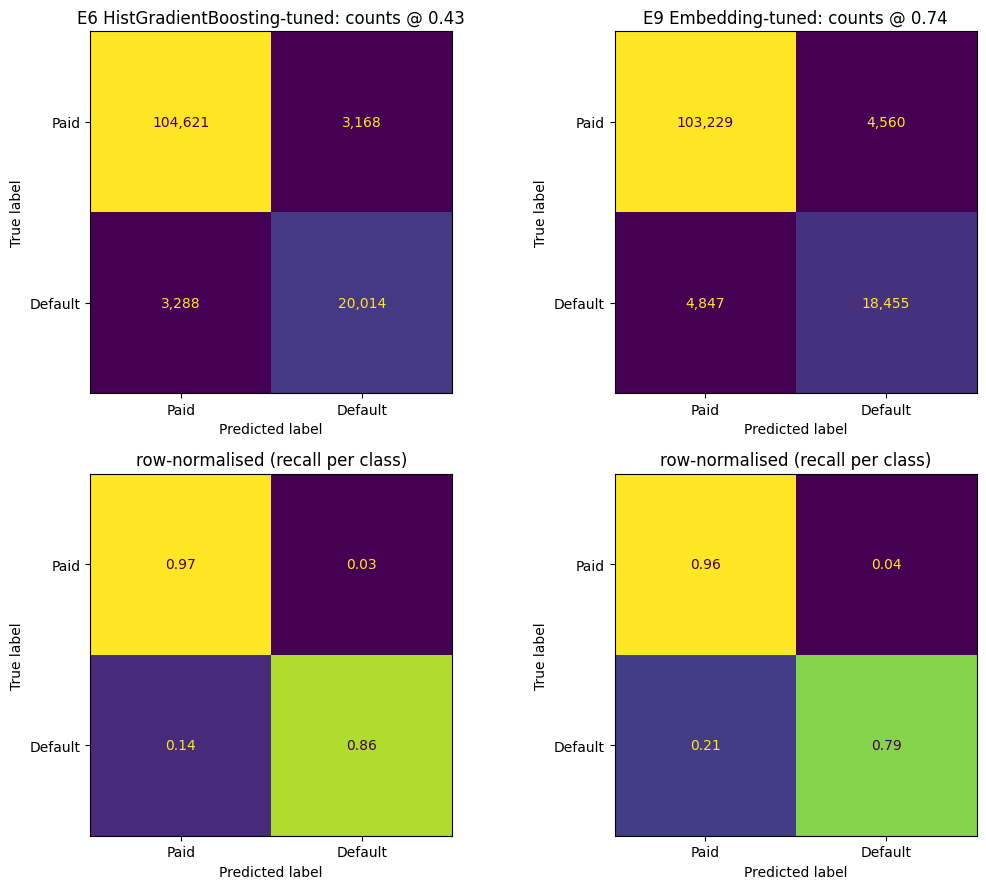

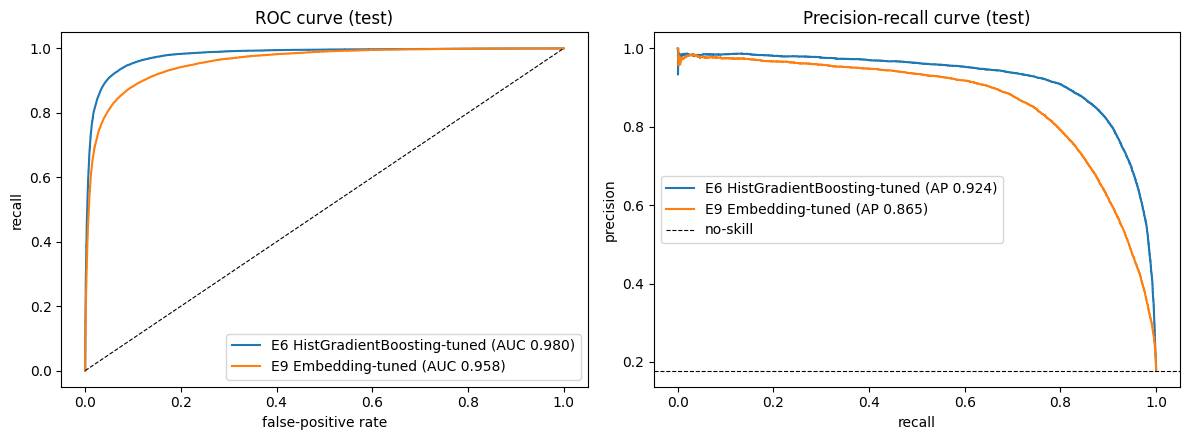

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for j, (k, p) in enumerate(TEST_PROBA.items()):
    pred = (p >= OP[k]).astype(int)
    cm = confusion_matrix(y_te, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Paid", "Default"]).plot(ax=axes[0, j], colorbar=False, values_format=",d")
    axes[0, j].set_title(f"{TEST_NAMES[k]}: counts @ {OP[k]:.2f}")
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, normalize="true"), display_labels=["Paid", "Default"]).plot(
        ax=axes[1, j], colorbar=False, values_format=".2f")
    axes[1, j].set_title("row-normalised (recall per class)")
plt.tight_layout(); plt.savefig(FIGS_DIR / "confusion_matrices.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, p in TEST_PROBA.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f"{TEST_NAMES[k]} (AUC {roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p); ax[1].plot(rc, pr, label=f"{TEST_NAMES[k]} (AP {average_precision_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(title="ROC curve (test)", xlabel="false-positive rate", ylabel="recall")
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=0.8, label="no-skill"); ax[1].set(title="Precision-recall curve (test)", xlabel="recall", ylabel="precision")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(FIGS_DIR / "roc_pr_curves.png", dpi=150); plt.show()

**✍️ Your interpretation (confusion matrices, ROC, PR).** Which kind of error dominates, false negatives (missed defaults) or false positives (good loans rejected), and what does that cost in each direction? Why is the precision-recall curve more informative than the ROC curve here? Do the two models differ materially, and is the difference large enough to matter?

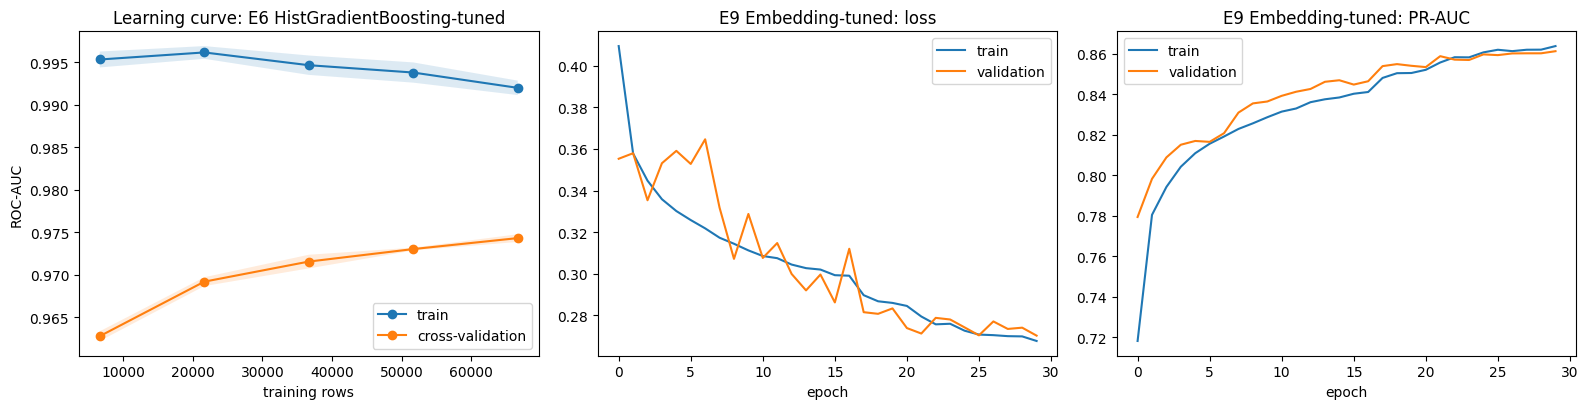

In [23]:
# Learning curve for the best traditional model (subsample for speed) + training curves for the best deep model
fs = STORE[BEST_CLASSICAL]["feature_set"]
idx = sample_rows(SPLITS["train"], TUNE_ROWS)
sizes, tr_sc, va_sc = learning_curve(clone(STORE[BEST_CLASSICAL]["pipe"]), get_X(df.iloc[idx], fs), y_all[idx],
                                     train_sizes=np.linspace(0.1, 1.0, 5), cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED),
                                     scoring="roc_auc", n_jobs=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(sizes, tr_sc.mean(1), "o-", label="train"); ax[0].plot(sizes, va_sc.mean(1), "o-", label="cross-validation")
ax[0].fill_between(sizes, tr_sc.mean(1) - tr_sc.std(1), tr_sc.mean(1) + tr_sc.std(1), alpha=0.15)
ax[0].fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.15)
ax[0].set(title=f"Learning curve: {LABEL[BEST_CLASSICAL]}", xlabel="training rows", ylabel="ROC-AUC"); ax[0].legend()
h = HISTORIES[BEST_NN]
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation"); ax[1].set(title=f"{LABEL[BEST_NN]}: loss", xlabel="epoch"); ax[1].legend()
ax[2].plot(h["pr_auc"], label="train"); ax[2].plot(h["val_pr_auc"], label="validation"); ax[2].set(title=f"{LABEL[BEST_NN]}: PR-AUC", xlabel="epoch"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIGS_DIR / "learning_curves.png", dpi=150); plt.show()

**n (learning curves).** Is there a persistent gap between the training and validation curves (variance, overfitting) or are both curves low and close (bias, underfitting)? Would more data help? For the neural network, at which epoch does validation PR-AUC stop improving, and what did early stopping and learning-rate reduction do? Relate these observations to the bias-variance trade-off.

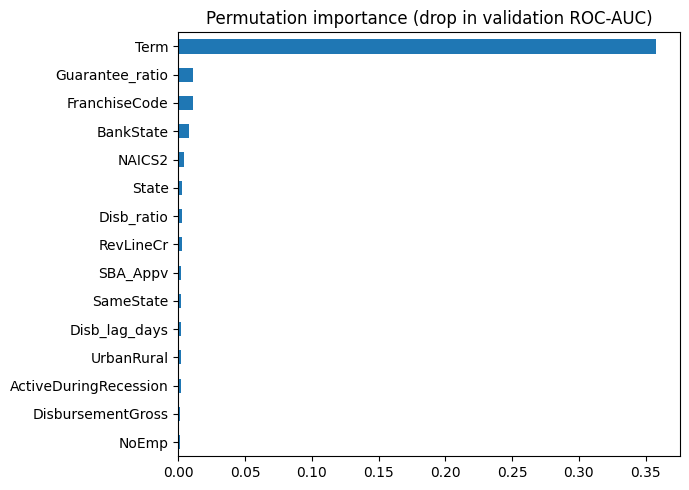

In [24]:
# Which original features matter? Permutation importance on a validation sample (traditional model)
s = STORE[BEST_CLASSICAL]
vi = sample_rows(SPLITS["val"], 20_000)
imp = permutation_importance(s["pipe"], get_X(df.iloc[vi], s["feature_set"]), y_all[vi], scoring="roc_auc",
                             n_repeats=3, random_state=SEED, n_jobs=1)
imp_df = pd.Series(imp.importances_mean, index=get_X(df.iloc[vi[:1]], s["feature_set"]).columns).sort_values()
imp_df.tail(15).plot.barh(figsize=(7, 5), title="Permutation importance (drop in validation ROC-AUC)")
plt.tight_layout(); plt.savefig(FIGS_DIR / "permutation_importance.png", dpi=150); plt.show()


=== CreatesJobs_lbl ===


,loans,default_rate,recall (defaults caught),false-positive rate (good loans flagged),precision
group,,,,,
no new jobs planned,91807,0.158,0.829,0.027,0.852
plans to create jobs,39284,0.225,0.908,0.035,0.881



=== NewExist_lbl ===


,loans,default_rate,recall (defaults caught),false-positive rate (good loans flagged),precision
group,,,,,
existing business,94288,0.172,0.866,0.026,0.873
new business,36803,0.192,0.842,0.038,0.842



=== UrbanRural_lbl ===


...

,loans,default_rate,recall (defaults caught),false-positive rate (good loans flagged),precision
group,,,,,
Q1 small,34643,0.286,0.943,0.036,0.912
Q2,31255,0.189,0.876,0.030,0.870
Q3,32547,0.135,0.795,0.028,0.817
Q4 large,32646,0.095,0.648,0.024,0.738



=== Sector ===


,loans,default_rate,recall (defaults caught),false-positive rate (good loans flagged),precision
group,,,,,
NAICS 23,9588,0.242,0.902,0.036,0.888
NAICS 44,12373,0.227,0.894,0.041,0.866
NAICS 54,9800,0.197,0.902,0.023,0.904
NAICS 72,9618,0.224,0.848,0.045,0.844
NAICS 81,10752,0.197,0.863,0.029,0.881
NAICS UNK,30044,0.082,0.656,0.020,0.749
other sectors,48916,0.194,0.884,0.030,0.875



=== ActiveDuringRecession ===


,loans,default_rate,recall (defaults caught),false-positive rate (good loans flagged),precision
group,,,,,
0,47642,0.179,0.835,0.039,0.824
1,83449,0.177,0.873,0.024,0.887


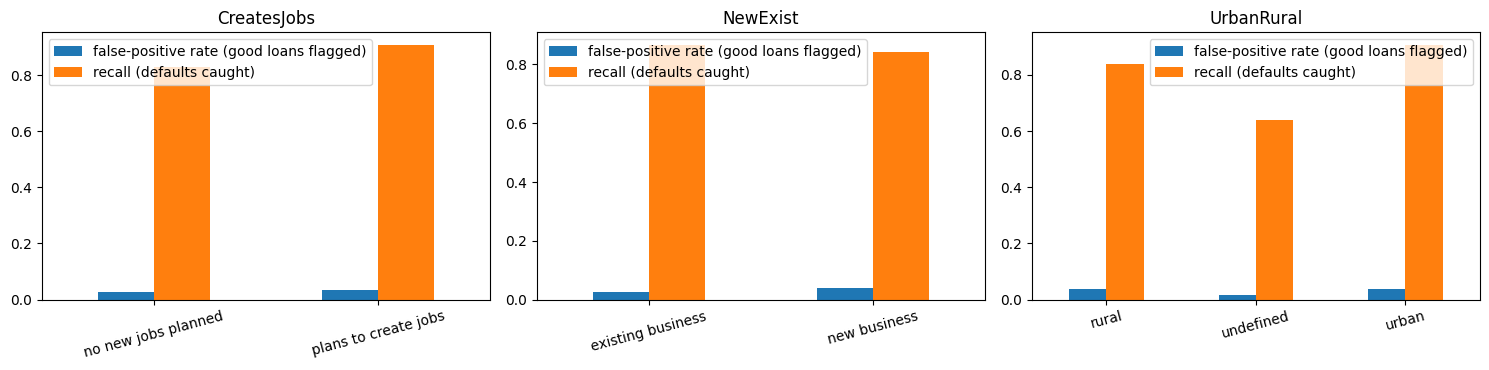

In [25]:
# Subgroup error analysis on the test set (traditional model at its F1-optimal threshold)
meta = df.iloc[te].reset_index(drop=True).copy()
meta["size_bucket"] = pd.qcut(meta["GrAppv"], 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"])
meta["CreatesJobs_lbl"] = np.where(meta["CreateJob"] > 0, "plans to create jobs", "no new jobs planned")
meta["NewExist_lbl"] = meta["NewExist"].map({"1": "existing business", "2": "new business"})
meta["UrbanRural_lbl"] = meta["UrbanRural"].map({"0": "undefined", "1": "urban", "2": "rural"})
top_sectors = meta["NAICS2"].value_counts().head(6).index
meta["Sector"] = np.where(meta["NAICS2"].isin(top_sectors), "NAICS " + meta["NAICS2"], "other sectors")

def group_error_table(meta, y, pred, col):
    rows = []
    for g, d in meta.groupby(col, observed=True):
        i = d.index.to_numpy(); yy, pp = y[i], pred[i]
        neg, pos = (yy == 0).sum(), (yy == 1).sum()
        rows.append({"group": g, "loans": len(i), "default_rate": yy.mean(),
                     "recall (defaults caught)": ((pp == 1) & (yy == 1)).sum() / max(pos, 1),
                     "false-positive rate (good loans flagged)": ((pp == 1) & (yy == 0)).sum() / max(neg, 1),
                     "precision": ((pp == 1) & (yy == 1)).sum() / max((pp == 1).sum(), 1)})
    return pd.DataFrame(rows).set_index("group").round(3)

pred_t = (TEST_PROBA["traditional"] >= OP["traditional"]).astype(int)
tables = {c: group_error_table(meta, y_te, pred_t, c) for c in
          ["CreatesJobs_lbl", "NewExist_lbl", "UrbanRural_lbl", "size_bucket", "Sector", "ActiveDuringRecession"]}
for c, t in tables.items():
    print(f"\n=== {c} ==="); display(t)
pd.concat(tables, names=["dimension"]).to_csv(RESULTS_DIR / "error_analysis_by_group.csv")

fpr_col = "false-positive rate (good loans flagged)"
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(ax, ["CreatesJobs_lbl", "NewExist_lbl", "UrbanRural_lbl"]):
    tables[c][[fpr_col, "recall (defaults caught)"]].plot.bar(ax=a, rot=15); a.set_title(c.replace("_lbl", "")); a.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGS_DIR / "error_by_group.png", dpi=150); plt.show()

 Are some groups wrongly flagged more often, for example new businesses, rural borrowers, or loans that plan to create jobs? If the false-positive rate is higher for a group, what would that mean for access to credit and jobs in that group? What could explain the pattern (class balance within the group, feature coverage, historical lending practice)? List dataset limitations you can now evidence: US-only data, one lender-side view, survivorship and censoring, missing borrower characteristics, and label definition (charge-off versus paid in full).

## 9b. E12: ablation without `Term` (leakage and robustness check)

`Term` is the strongest single predictor in this dataset and is debated as a possible proxy for the outcome (long terms usually mean real-estate collateral, and the field may be recorded differently for loans that end early). E12 refits the tuned gradient-boosting configuration from E6 without `Term` and without `ActiveDuringRecession` (which is computed from `Term`). Only the validation split is used, so the test set stays untouched. A large drop means the headline scores lean heavily on one variable and should be reported with that caveat.

In [26]:
num, binary, cat = FEATURE_SETS["engineered"]
FEATURE_SETS["engineered_no_term"] = ([c for c in num if c != "Term"],
                                      [c for c in binary if c != "ActiveDuringRecession"], cat)
hgb_e6 = clone(STORE["E6"]["pipe"].named_steps["clf"])      # same tuned hyper-parameters as E6
_ = run_classical("E12", "HGB-tuned-no-Term", hgb_e6, feature_set="engineered_no_term")
yv = y_all[SPLITS["val"]]
print("PR-AUC change vs E6:", round(average_precision_score(yv, STORE["E12"]["val_proba"])
                                   - average_precision_score(yv, STORE["E6"]["val_proba"]), 4))


exp                             E12
model             HGB-tuned-no-Term
features         engineered_no_term
eval_on                         val
accuracy                     0.8537
precision                    0.6734
recall                       0.3435
f1                            0.455
roc_auc                      0.8375
pr_auc                       0.5749
train_roc_auc                0.8621
auc_gap                      0.0246
fit_seconds                   111.2
PR-AUC change vs E6: -0.3461


## 10. Experiment table, saved models, Drive export

**Fill in the `observations` dictionary** with one or two sentences per experiment explaining *why* the result changed (not just that it did). The rubric rewards insight beyond the numbers. The final table is saved to `outputs/results/experiment_table.csv` and mirrors the W&B offline and TensorBoard logs.

In [27]:
OBSERVATIONS = {
    "E1": "TODO: baseline logistic regression, what does it capture and what does it miss?",
    "E2": "TODO: effect of engineered features",
    "E3": "TODO: effect of class weights on precision / recall",
    "E4": "TODO", "E5": "TODO", "E6": "TODO", "E7": "TODO", "E8": "TODO", "E9": "TODO",
    "E10": "TODO: threshold trade-off", "E11": "TODO: drift under the time split",
    "E12": "TODO: how much of the performance depends on Term?",
}
table = pd.DataFrame(RESULTS)
table["observations"] = table["exp"].map(OBSERVATIONS).fillna("")
table.to_csv(RESULTS_DIR / "experiment_table.csv", index=False)
final_df.to_csv(RESULTS_DIR / "final_test_metrics.csv", index=False)
display(table.drop(columns=["params"]))
try:
    print(table.drop(columns=["params"]).to_markdown(index=False))
except Exception:
    pass

,exp,model,paradigm,features,split,eval_on,accuracy,balanced_acc,precision,recall,f1,mcc,roc_auc,pr_auc,train_roc_auc,auc_gap,fit_seconds,observations
0,E1,LogReg-baseline,traditional ML,base,random,val,0.8601,0.6558,0.7293,0.3388,0.4626,0.4328,0.8521,0.5956,0.8527,0.0006,24.3,"TODO: baseline logistic regression, what does ..."
1,E2,LogReg+features,traditional ML,engineered,random,val,0.8727,0.6882,0.7731,0.4019,0.5289,0.4969,0.8623,0.6422,0.8641,0.0018,23.8,TODO: effect of engineered features
2,E3,LogReg+features+classweight,traditional ML,engineered,random,val,0.7456,0.7772,0.3966,0.8262,0.5359,0.4389,0.8570,0.6046,0.8596,0.0026,32.2,TODO: effect of class weights on precision / r...
3,E4,RandomForest-default,traditional ML,engineered,random,val,0.9212,0.8887,0.7486,0.8382,0.7909,0.7444,0.9554,0.8648,0.9861,0.0307,68.6,TODO
4,E5,RandomForest-tuned,traditional ML,engineered,random,val,0.9264,0.9083,0.7495,0.8802,0.8096,0.7681,0.9708,0.8940,0.9867,0.0159,104.9,TODO
5,E6,HistGradientBoosting-tuned,traditional ML,engineered,random,val,0.9513,0.9066,0.8829,0.8373,0.8595,0.8305,0.9793,0.9209,0.9896,0.0103,259.9,TODO
6,E7,MLP-sequential,deep learning,engineered,random,val,0.8831,0.8694,0.6265,0.8481,0.7206,0.6607,0.9400,0.8290,0.9551,0.0151,154.0,TODO
7,E8,Embedding-functional,deep learning,engineered,random,val,0.8790,0.8742,0.6129,0.8668,0.7180,0.6596,0.9447,0.8367,0.9517,0.0070,420.9,TODO
8,E9,Embedding-tuned,deep learning,engineered,random,val,0.8980,0.8908,0.6598,0.8796,0.7540,0.7027,0.9556,0.8620,0.9677,0.0121,488.8,TODO
9,E10,HistGradientBoosting-tuned@f1_opt,traditional ML,engineered,random,val(tuned),0.9507,0.9141,0.8642,0.8574,0.8607,0.8308,0.9793,0.9209,NaN,NaN,NaN,TODO: threshold trade-off


| exp   | model                                  | paradigm       | features           | split   | eval_on       |   accuracy |   balanced_acc |   precision |   recall |     f1 |    mcc |   roc_auc |   pr_auc |   train_roc_auc |   auc_gap |   fit_seconds | observations                                                                    |
|:------|:---------------------------------------|:---------------|:-------------------|:--------|:--------------|-----------:|---------------:|------------:|---------:|-------:|-------:|----------:|---------:|----------------:|----------:|--------------:|:--------------------------------------------------------------------------------|
| E1    | LogReg-baseline                        | traditional ML | base               | random  | val           |     0.8601 |         0.6558 |      0.7293 |   0.3388 | 0.4626 | 0.4328 |    0.8521 |   0.5956 |          0.8527 |    0.0006 |          24.3 | TODO: baseline logistic regression, what does it capture and what

In [28]:
# Save the best model of each paradigm (these go into the Google Drive folder, not GitHub)
joblib.dump(STORE[BEST_CLASSICAL]["pipe"], MODELS_DIR / "best_traditional_model.joblib")
nn_best = STORE[BEST_NN]
nn_best["model"].save(MODELS_DIR / "best_deep_model.keras")
try:
    nn_best["model"].save(MODELS_DIR / "best_deep_model.h5")      # legacy format also accepted by the brief
except Exception as e:
    print("h5 export skipped:", e)
joblib.dump(nn_best["prep"], MODELS_DIR / "deep_model_preprocessor.joblib")
print("Saved:", sorted(p.name for p in MODELS_DIR.iterdir()))
print("Note: to reload the joblib files elsewhere, first run the cells that define Winsorizer / NNPrep.")

Saved: ['best_deep_model.h5', 'best_deep_model.keras', 'best_traditional_model.joblib', 'deep_model_preprocessor.joblib']
Note: to reload the joblib files elsewhere, first run the cells that define Winsorizer / NNPrep.


In [29]:

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
SAVE_TO_DRIVE = IN_COLAB          # skipped automatically outside Colab
if SAVE_TO_DRIVE:
    drive.mount("/content/drive")
    target = Path("/content/drive/MyDrive/sba_project_deliverables"); target.mkdir(exist_ok=True)
    shutil.make_archive(str(target / "SBAnational_raw"), "zip", root_dir=str(data_path.parent), base_dir=data_path.name)
    shutil.copytree(MODELS_DIR, target / "models", dirs_exist_ok=True)
    shutil.copytree(RESULTS_DIR, target / "results", dirs_exist_ok=True)
    shutil.copytree(WANDB_DIR, target / "wandb_offline_logs", dirs_exist_ok=True)
    shutil.copytree(TB_DIR, target / "tensorboard_logs", dirs_exist_ok=True)
    print("Copied to", target, "- now set sharing to 'Anyone with the link can view'.")

Mounted at /content/drive
Copied to /content/drive/MyDrive/sba_project_deliverables - now set sharing to 'Anyone with the link can view'.
